In [1]:

# QUESTION 2: TITANIC SURVIVAL CLASSIFICATION

# Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Machine learning libraries
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import LabelEncoder

# Model evaluation
from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix
from sklearn.metrics import classification_report

print("Libraries imported successfully!")


Libraries imported successfully!


In [2]:

# Load Titanic dataset
df = pd.read_csv("Titanic.csv")

# Display first 5 rows
df.head()


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [3]:

# Check dataset dimensions
print("Dataset shape:", df.shape)

# Check data types
print("\nData types:")
print(df.dtypes)

# Check missing values
print("\nMissing values:")
print(df.isnull().sum())

# Check duplicates
print("\nDuplicates:", df.duplicated().sum())

# Display summary statistics
df.describe()


Dataset shape: (891, 12)

Data types:
PassengerId      int64
Survived         int64
Pclass           int64
Name               str
Sex                str
Age            float64
SibSp            int64
Parch            int64
Ticket             str
Fare           float64
Cabin              str
Embarked           str
dtype: object

Missing values:
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

Duplicates: 0


,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


### Descriptive Statistics

The Titanic dataset contains 891 passenger records. The descriptive statistics show that approximately 38.4% of passengers survived. The average age of passengers with recorded ages was approximately 30 years, with ages ranging from 0.42 to 80 years.

The average passenger fare was approximately 32.20, while passenger classes ranged from first to third class. The Age column contained missing values, indicating the need for data cleaning before building the classification models.

In [4]:

# Select required columns
titanic = df[['Survived', 'Age', 'Sex',
              'Pclass', 'Fare', 'Embarked']].copy()

# Fill missing values
titanic['Age'] = titanic['Age'].fillna(titanic['Age'].median())
titanic['Embarked'] = titanic['Embarked'].fillna(
    titanic['Embarked'].mode()[0]
)

# Encode categorical variables
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()

titanic['Sex'] = le.fit_transform(titanic['Sex'])
titanic['Embarked'] = le.fit_transform(titanic['Embarked'])

# Display cleaned data
titanic.head()

,Survived,Age,Sex,Pclass,Fare,Embarked
0,0,22.0,1,3,7.2500,2
1,1,38.0,0,1,71.2833,0
2,1,26.0,0,3,7.9250,2
3,1,35.0,0,1,53.1000,2
4,0,35.0,1,3,8.0500,2


In [5]:

# Check missing values after cleaning
titanic.isnull().sum()

Survived    0
Age         0
Sex         0
Pclass      0
Fare        0
Embarked    0
dtype: int64

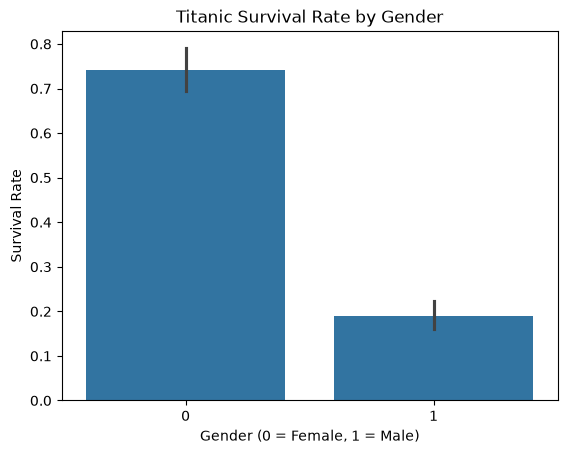

In [6]:

# Survival rate by gender

sns.barplot(data=titanic, x='Sex', y='Survived')

plt.title('Titanic Survival Rate by Gender')
plt.xlabel('Gender (0 = Female, 1 = Male)')
plt.ylabel('Survival Rate')

plt.show()

### Interpretation: Titanic Survival Rate by Gender

The bar chart shows that female passengers had a significantly higher survival rate than male passengers aboard the Titanic.

Approximately 74% of female passengers survived, compared to only 19% of male passengers.

This suggests that gender was an important factor associated with survival, with female passengers having a greater chance of surviving than male passengers.

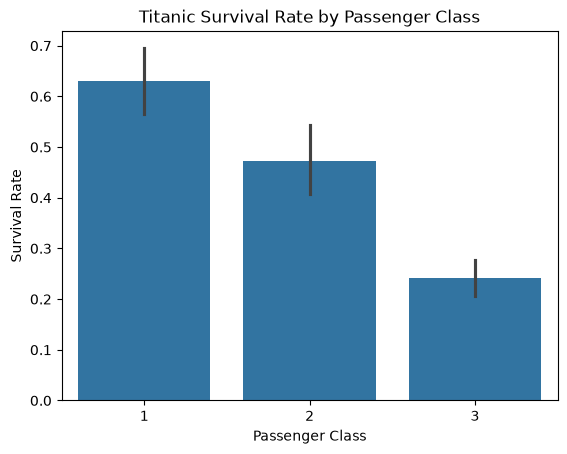

In [7]:

# Survival rate by passenger class

sns.barplot(data=titanic, x='Pclass', y='Survived')

plt.title('Titanic Survival Rate by Passenger Class')
plt.xlabel('Passenger Class')
plt.ylabel('Survival Rate')

plt.show()

### Interpretation: Titanic Survival Rate by Passenger Class

The bar chart shows that survival rates differed across the three passenger classes.

First-class passengers had the highest survival rate at approximately 63%, followed by second-class passengers at 47%. Third-class passengers had the lowest survival rate at approximately 24%.

These findings suggest that passenger class was associated with survival chances. Passengers travelling in higher classes were more likely to survive than those in lower classes.

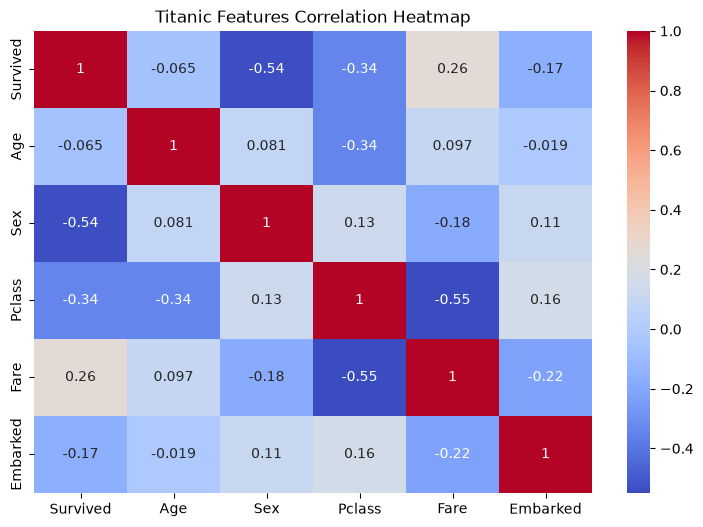

In [8]:

# Calculate correlation
correlation = titanic.corr()

# Plot correlation heatmap
plt.figure(figsize=(9, 6))

sns.heatmap(correlation, annot=True, cmap='coolwarm')

plt.title('Titanic Features Correlation Heatmap')

plt.show()


### Interpretation: Titanic Correlation Heatmap

The correlation heatmap shows the relationships between passenger characteristics and survival aboard the Titanic.

Sex had the strongest relationship with survival, with a correlation coefficient of -0.54, indicating that male passengers were less likely to survive than female passengers.

Passenger class also showed a negative correlation of -0.34, suggesting that passengers in lower classes had lower survival rates. Fare had a weak positive correlation of 0.26, indicating that passengers who paid higher fares were somewhat more likely to survive.

Age showed a very weak negative correlation with survival at -0.065.

Overall, the results suggest that gender and passenger class were the most strongly associated with survival among the variables examined. However, correlation does not necessarily imply causation.

In [9]:

# Independent variables (features)
X = titanic[['Age', 'Sex', 'Pclass', 'Fare', 'Embarked']]

# Dependent variable (target)
y = titanic['Survived']

# Check dimensions
print("Features:", X.shape)
print("Target:", y.shape)


Features: (891, 5)
Target: (891,)


In [10]:

# Split the dataset into training and testing sets

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)


Training data: (712, 5)
Testing data: (179, 5)


In [11]:

# Create Logistic Regression model
log_model = LogisticRegression(max_iter=1000)

# Train the model
log_model.fit(X_train, y_train)

# Make predictions
log_predictions = log_model.predict(X_test)

print("Logistic Regression trained successfully!")

Logistic Regression trained successfully!


In [12]:

# Create Random Forest model
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

# Train the model
rf_model.fit(X_train, y_train)

# Make predictions
rf_predictions = rf_model.predict(X_test)

print("Random Forest trained successfully!")


Random Forest trained successfully!


In [13]:

# Calculate model accuracy
log_accuracy = accuracy_score(y_test, log_predictions)
rf_accuracy = accuracy_score(y_test, rf_predictions)

print("Logistic Regression Accuracy:", round(log_accuracy * 100, 2), "%")
print("Random Forest Accuracy:", round(rf_accuracy * 100, 2), "%")

Logistic Regression Accuracy: 77.09 %
Random Forest Accuracy: 83.24 %


### Model Accuracy Comparison

Two classification models were developed to predict passenger survival: Logistic Regression and Random Forest.

The Logistic Regression model achieved an accuracy of 77.09%, while the Random Forest model achieved 83.24%.

The results show that Random Forest performed better than Logistic Regression on the test dataset, with an accuracy difference of 6.15 percentage points.

Therefore, Random Forest was the better-performing model based on accuracy in this analysis.

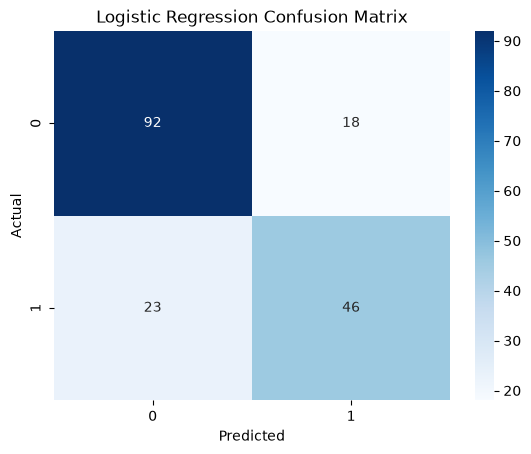

In [14]:

# Confusion Matrix for Logistic Regression

cm_log = confusion_matrix(y_test, log_predictions)

sns.heatmap(cm_log, annot=True, fmt='d', cmap='Blues')

plt.title('Logistic Regression Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')

plt.show()

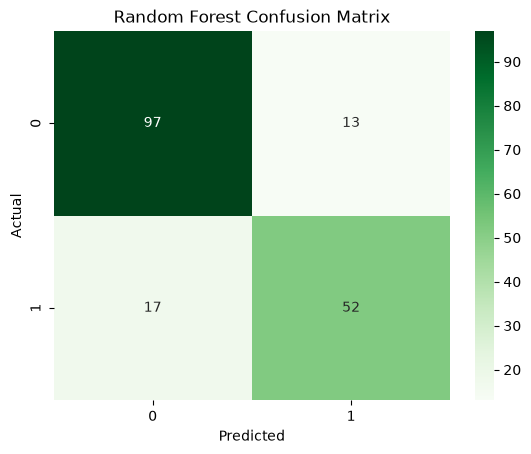

In [15]:

# Confusion Matrix for Random Forest

cm_rf = confusion_matrix(y_test, rf_predictions)

sns.heatmap(cm_rf, annot=True, fmt='d', cmap='Greens')

plt.title('Random Forest Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')

plt.show()

In [16]:

# Logistic Regression Classification Report

print("Logistic Regression Classification Report")
print(classification_report(y_test, log_predictions))

# Random Forest Classification Report

print("Random Forest Classification Report")
print(classification_report(y_test, rf_predictions))


Logistic Regression Classification Report
              precision    recall  f1-score   support

           0       0.80      0.84      0.82       110
           1       0.72      0.67      0.69        69

    accuracy                           0.77       179
   macro avg       0.76      0.75      0.75       179
weighted avg       0.77      0.77      0.77       179

Random Forest Classification Report
              precision    recall  f1-score   support

           0       0.85      0.88      0.87       110
           1       0.80      0.75      0.78        69

    accuracy                           0.83       179
   macro avg       0.83      0.82      0.82       179
weighted avg       0.83      0.83      0.83       179



### Model Evaluation and Comparison

The Logistic Regression and Random Forest models were evaluated using accuracy scores, confusion matrices and classification reports.

The Logistic Regression model achieved an accuracy of 77.09%, correctly predicting 138 out of 179 passengers. The Random Forest model achieved a higher accuracy of 83.24%, correctly predicting 149 passengers.

The confusion matrices showed that Random Forest made fewer incorrect predictions, with 30 errors compared to 41 errors made by Logistic Regression.

For passengers who survived, Random Forest achieved a precision of 0.80, recall of 0.75 and F1-score of 0.78. These values were higher than those of Logistic Regression, which achieved 0.72, 0.67 and 0.69 respectively.

Overall, Random Forest performed better than Logistic Regression in predicting passenger survival on the test dataset.

### Conclusion

The Titanic Survival Classification analysis examined how passenger characteristics influenced survival and used machine learning models to predict survival outcomes.

The exploratory analysis showed that gender and passenger class were important factors associated with survival. Female passengers had higher survival rates than male passengers, while first-class passengers had better survival outcomes than those in second and third class.

Two classification models, Logistic Regression and Random Forest, were developed and evaluated. Random Forest achieved the highest accuracy of 83.24%, compared to 77.09% for Logistic Regression.

The findings demonstrate how basic data cleaning, exploratory data analysis and machine learning techniques can be used to identify patterns and predict outcomes.

Based on the evaluation results, Random Forest was the better-performing model for this dataset.